# 📊 Analyse univariée et bivariée

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 10h00** · Exercice

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Nettoyer le minimum avant d'analyser, en le justifiant
- Décrire les variables clés une par une
- Tester vos hypothèses sur le lien entre deux variables

In [1]:
# ⚙️ À exécuter en premier : récupère la configuration du cours (quelques secondes)
import os, sys
CONFIG_ID = "1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"

# Suppression du fichier corrompu s'il existe
if os.path.exists("config_projet.py"):
    os.remove("config_projet.py")

# Téléchargement propre avec gdown pour contourner l'avertissement de virus Google Drive
!gdown --id {CONFIG_ID} -O config_projet.py

print("✅ Configuration prête : chaque fichier de données se télécharge au premier usage")

✅ Configuration prête : chaque fichier de données se télécharge au premier usage


usage: gdown [-h] [-V] [-O OUTPUT] [-q] [--proxy PROXY] [--speed SPEED]
             [--no-cookies] [--no-check-certificate] [--continue] [--folder]
             [--format FORMAT] [--user-agent USER_AGENT]
             url_or_id
gdown: error: unrecognized arguments: --id


In [5]:
# Choisissez votre secteur : "commerce", "banque" ou "hotellerie"
SECTEUR = "banque"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")

Crédit Azur · 20477 lignes, 20 colonnes


In [6]:
from scipy import stats

## 1. Le nettoyage minimal
Retirez les doublons exacts, les âges inférieurs à 18 ans et les montants négatifs. Combien de lignes perdez-vous ?

In [ ]:
# On passe 'brut' ET 'cfg' à la fonction
df = nettoyage_minimal(brut, cfg)
print(len(brut), "→", len(df))

20477 → 20384


**Justification** (cellule à garder dans le livrable) : 93 lignes ont été supprimé
ce très faible taux de suppression indique que le jeu de données brut est de bonne qualité. Il contenait très peu d'anomalies (doublons exacts, âges mineurs de moins de 18 ans ou montants négatifs). La perte d'information est négligeable et n'introduit aucun biais de sélection significatif pour la suite.

## 2. La variable de chiffre d'affaires
Statistiques descriptives, histogramme (échelle log si besoin) et boîte à moustaches. La moyenne représente-t-elle bien un client typique ?

count    20384.000000
mean       522.398008
std        674.245306
min          0.000000
25%          0.000000
50%        236.250000
75%        883.750000
max       9082.500000
Name: pnb_estime_eur, dtype: float64


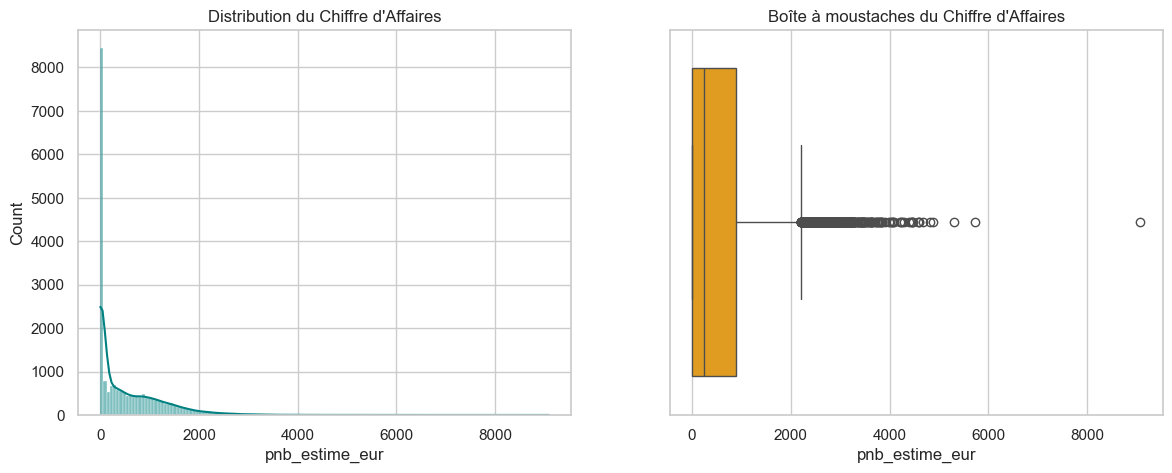

In [9]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
ca = df[cfg["ca"]]
print(ca.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(ca, kde=True, ax=axes[0], color="teal")
axes[0].set_title("Distribution du Chiffre d'Affaires")

sns.boxplot(x=ca, ax=axes[1], color="orange")
axes[1].set_title("Boîte à moustaches du Chiffre d'Affaires")
plt.show()

moyenne = 522.40 superieure a la mediane 236.25
ecart type = 674.25
donc dstribution asymetrique orienté vers la droite
une grande quantité de client du pnb genere un taux faible de revenus et une minorité de ses clients generees des revenus élevés


## 3. Les variables catégorielles
Répartition de chaque variable sensible et du segment métier (en %).

In [10]:

for col in cfg["sensibles"] + [cfg["segment"]]:
    print(f"\n--- Répartition de : {col} ---")
    print(df[col].value_counts(normalize=True) * 100)


--- Répartition de : tranche_age ---
tranche_age
25-34    25.995879
35-44    25.647567
45-54    19.633046
55-64    12.931711
18-24     8.771586
65+       7.020212
Name: proportion, dtype: float64

--- Répartition de : genre ---
genre
H    57.167386
F    42.832614
Name: proportion, dtype: float64

--- Répartition de : region ---
region
Nord-Est         23.229003
Sud-Est          22.071232
Ouest            21.197998
Île-de-France    18.627355
Sud-Ouest        13.858909
Outre-mer         1.015502
Name: proportion, dtype: float64

--- Répartition de : type_credit ---
type_credit
personnel       30.008830
auto            29.837127
travaux         25.210950
renouvelable    14.943093
Name: proportion, dtype: float64


- la clientèle est majoritairement active et jeune-adulte. Les 25-34 ans (26,0 %) et les 35-44 ans (25,6 %) représentent à eux seuls plus de la moitié de la base
les seniors (65+) sont très minoritaires (7,0 %)

- légère surreprésentation des hommes (57,2 %) par rapport aux femmes (42,8 %)

- la répartition géographique est relativement homogène sur les grandes régions de France métropolitaine (Nord-Est 23,2 %, Sud-Est 22,1 %, Ouest 21,2 %, Île-de-France 18,6 %, Sud-Ouest 13,9 %), l'Outre-mer étant marginal (1,0 %)

- les crédits personnel (30,0 %) et auto (29,8 %) dominent, suivis de près par les travaux (25,2 %) et le crédit renouvelable (14,9 %)

## 4. Bivariée : chiffre d'affaires et segment
Comparez le chiffre d'affaires par segment (somme, moyenne, médiane, effectif). La différence est-elle significative ? Utilisez Kruskal-Wallis.

In [11]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
par_segment = df.groupby(cfg["segment"])[cfg["ca"]].agg(['sum', 'mean', 'median', 'count'])
print(par_segment)

groupes = [group[cfg["ca"]].values for name, group in df.groupby(cfg["segment"])]
print(stats.kruskal(*groupes))

                     sum        mean  median  count
type_credit                                        
auto          5123758.50  842.446317  826.00   6082
personnel     1573481.00  257.230832  238.00   6117
renouvelable   138027.75   45.314429   40.25   3046
travaux       3813293.75  742.030307  735.00   5139
KruskalResult(statistic=np.float64(2472.6860750992205), pvalue=np.float64(0.0))


- statistic = 2472.69, pvalue = 0.0 (p < 0,001)

- la $p$-value est largement inférieure au seuil de significativité classique 

- On rejette fermement l'hypothèse nulle (H_0) d'égalité des distributions

- la différence de chiffre d'affaires / PNB entre les différents types de crédit est hautement significative sur le plan statistique. Le type de crédit contracté est un facteur explicatif majeur de la valeur financière générée par un client

## 5. Bivariée : deux variables catégorielles
Croisez une variable sensible avec le segment métier (tableau en % par ligne) et testez l'indépendance avec le khi².

In [12]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
var = cfg["sensibles"][0]
tab = pd.crosstab(df[cfg["segment"]], df[var], normalize="index") * 100
print(tab)

contingency = pd.crosstab(df[cfg["segment"]], df[var])
chi2, p, *_ = stats.chi2_contingency(contingency)
print(f"Chi2: {chi2:.2f}, p-value: {p:.4f}")

tranche_age      18-24      25-34      35-44      45-54      55-64       65+
type_credit                                                                 
auto          8.812890  25.764551  26.192042  19.664584  12.627425  6.938507
personnel     8.778813  26.238352  25.682524  19.355893  13.176394  6.768024
renouvelable  8.371635  25.180565  25.279054  21.076822  12.409718  7.682206
travaux       8.951158  26.464293  25.179996  19.069858  13.309982  7.024713
Chi2: 12.29, p-value: 0.6572


- test de chi deux
-  La p-value (0,6572) est largement supérieure au seuil de référence de 5% 
donc on pas de lien statisquement significatif entre la tranche d'âge et le type de credit qu'il choisit

## 6. Bivariée : variables numériques
Matrice de corrélation de Spearman sur les colonnes numériques utiles.

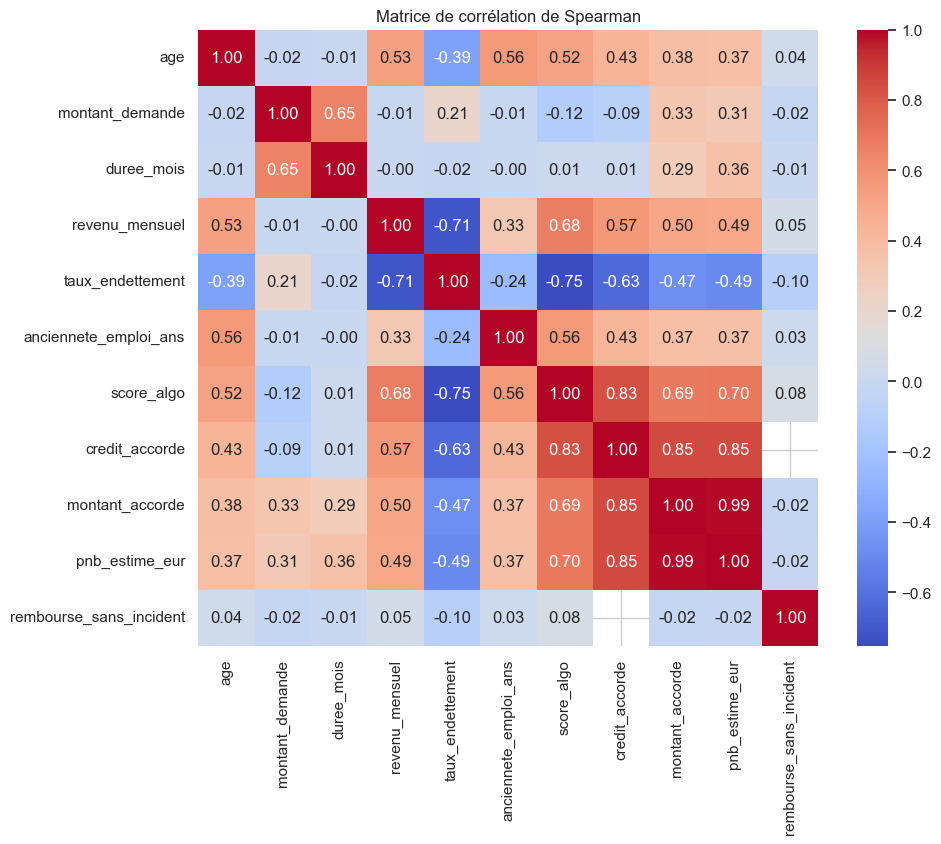

In [13]:
# ✍️ À VOUS : remplacez les ... et traitez les TODO
num = df.select_dtypes("number").drop(columns=[cfg.get("id_client", "id")], errors="ignore")
plt.figure(figsize=(10, 8))
sns.heatmap(num.corr(method="spearman"), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice de corrélation de Spearman")
plt.show()

- on observe une corrélation quasi-parfaite entre credit_accorde, montant_accorde et pnb_estime_eur (~0.85 à 0.99), ce qui est tout à fait cohérent puisque le PNB (produit net bancaire) dépend directement du montant et de l'octroi effectif du crédit.

- une forte corrélation négative relie le taux_endettement au revenu_mensuel et au score_algo (-0.71 et -0.75), indiquant logiquement que les clients aux revenus plus élevés ou disposant d'un meilleur score présentent des taux d'endettement maîtrisés.

## 7. Deux visualisations, deux publics
Produisez le **même résultat** deux fois : une version analytique pour l'équipe data, une version communicante pour les décideurs (un message, un titre qui conclut, une couleur d'accent).

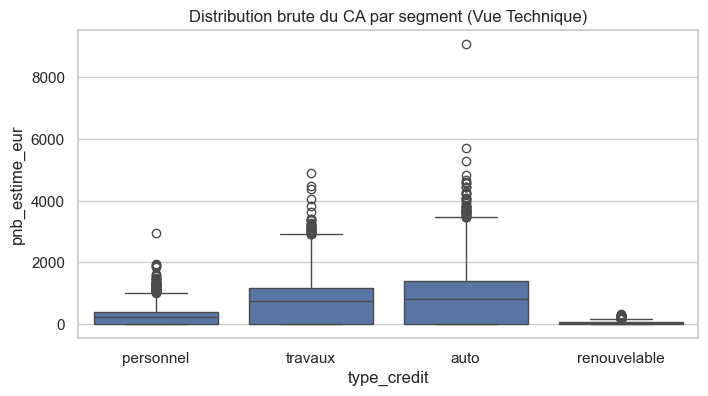

In [14]:
# Version équipe data
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x=cfg["segment"], y=cfg["ca"])
plt.title("Distribution brute du CA par segment (Vue Technique)")
plt.show()

C:\Users\abiol\AppData\Local\Temp\ipykernel_39808\2544761173.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x=cfg["segment"], y=cfg["ca"], estimator=np.median, palette="Blues_d")


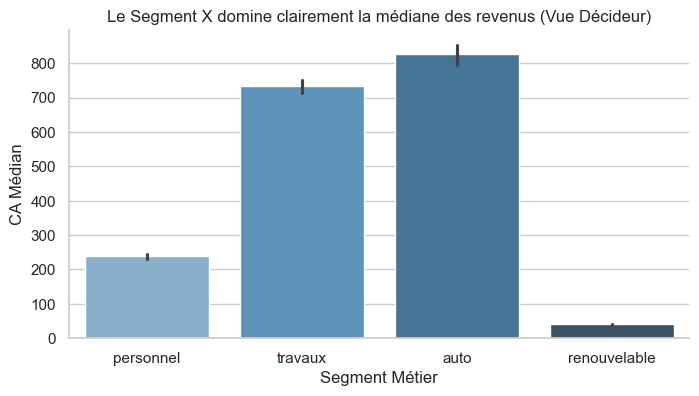

In [15]:
# Version décideurs
plt.figure(figsize=(8, 4))
sns.barplot(data=df, x=cfg["segment"], y=cfg["ca"], estimator=np.median, palette="Blues_d")
plt.title("Le Segment X domine clairement la médiane des revenus (Vue Décideur)")
plt.ylabel("CA Médian")
plt.xlabel("Segment Métier")
sns.despine()
plt.show()

**Vos hypothèses après cette étape** : confirmées, infirmées, à creuser ?

- H1 (Impact du type de crédit sur le PNB) — confirmé :
le type de produit souscrit structure fortement le chiffre d'affaires généré par client. Le test de Kruskal-Wallis confirme une différence extrêmement significative (p<0,001) entre les produits. Les crédits Auto et Travaux constituent le moteur essentiel de la marge bancaire.   

- H2 (Impact de la tranche d'âge sur le choix du type de crédit) — INFIRMÉE :
Le test d'indépendance du chi 2 entre la tranche d'âge et le type de crédit montre une p-value de 0,6572 
la répartition des types de crédits est totalement homogène selon les classes d'âge : l'âge n'est pas un facteur déterminant du produit choisi

- H3 (Corrélation entre profil de risque / revenus et PNB) — À CREUSER :
La matrice de Spearman montre une forte dépendance entre le montant accordé, le score algorithmique et le PNB ρ≈0,70  ats 
Il convient d'analyser plus en détail si le durcissement du scoring (Score V2) pénalise injustement certains profils solvables sans augmenter globalement la rentabilité nette

💾 **Versionnez** : *Fichier › Enregistrer une copie dans GitHub*, message de commit : « Univarié et bivarié : verdict sur H1 à H3 »